# EA2 – Modelos de predicción y clasificación

**Dataset:** [`ADAMlam-16/coffee-data_eda-project`](https://huggingface.co/datasets/ADAMlam-16/coffee-data_eda-project) (split `train`, 10.000 filas, 16 columnas).

Contiene datos de consumo de café y salud de personas de distintos países: edad, género, país, tazas de café al día, cafeína (mg), horas de sueño, calidad del sueño, BMI, ritmo cardíaco, nivel de estrés, actividad física, problemas de salud, ocupación, tabaco y alcohol.

**Columnas relevantes:** `Sleep_Hours` (objetivo de la regresión), `Stress_Level` (objetivo de la clasificación) y `Coffee_Intake`, `Age`, `BMI`, `Heart_Rate`, `Physical_Activity_Hours`, `Smoking`, `Alcohol_Consumption`, `Gender`, `Country` y `Occupation` (predictoras).

El dataset se descarga automáticamente con la clase `HFDatasetLoader`; no requiere archivos manuales.

In [31]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / "src" / "clases_po").exists():
    ROOT = ROOT.parent

sys.path.insert(0, str(ROOT / "src"))

from clases_po import HFDatasetLoader, Reportes

In [32]:
DATASET = "ADAMlam-16/coffee-data_eda-project"
SPLIT = "train"

loader = HFDatasetLoader(DATASET, split=SPLIT, filename="datos/coffee_health.csv")
df = loader.load()

print(loader.info())
df.head()

{'dataset': 'ADAMlam-16/coffee-data_eda-project', 'config': None, 'split': 'train', 'filas': 10000, 'columnas': 16}


,ID,Age,Gender,Country,Coffee_Intake,Caffeine_mg,Sleep_Hours,Sleep_Quality,BMI,Heart_Rate,Stress_Level,Physical_Activity_Hours,Health_Issues,Occupation,Smoking,Alcohol_Consumption
0,1,40,Male,Germany,3.5,328.1,7.5,Good,24.9,78,Low,14.5,NaN,Other,0,0
1,2,33,Male,Germany,1.0,94.1,6.2,Good,20.0,67,Low,11.0,NaN,Service,0,0
2,3,42,Male,Brazil,5.3,503.7,5.9,Fair,22.7,59,Medium,11.2,Mild,Office,0,0
3,4,53,Male,Germany,2.6,249.2,7.3,Good,24.7,71,Low,6.6,Mild,Other,0,0
4,5,32,Female,Spain,3.1,298.0,5.3,Fair,24.1,76,Medium,8.5,Mild,Student,0,1


In [33]:
reportes = Reportes()
reportes.imprimir_reporte(df)
ruta_reporte = reportes.guardar_reporte(df, "reportes/reporte_dataframe_inicial.txt")
print("\nReporte guardado en:", ruta_reporte)

REPORTE DEL DATAFRAME
Filas: 10000
Columnas: 16
Duplicados: 0

Columnas y tipos:
- ID: int64
- Age: int64
- Gender: str
- Country: str
- Coffee_Intake: float64
- Caffeine_mg: float64
- Sleep_Hours: float64
- Sleep_Quality: str
- BMI: float64
- Heart_Rate: int64
- Stress_Level: str
- Physical_Activity_Hours: float64
- Health_Issues: str
- Occupation: str
- Smoking: int64
- Alcohol_Consumption: int64

Valores nulos por columna:
- ID: 0
- Age: 0
- Gender: 0
- Country: 0
- Coffee_Intake: 0
- Caffeine_mg: 0
- Sleep_Hours: 0
- Sleep_Quality: 0
- BMI: 0
- Heart_Rate: 0
- Stress_Level: 0
- Physical_Activity_Hours: 0
- Health_Issues: 5941
- Occupation: 0
- Smoking: 0
- Alcohol_Consumption: 0

Estadísticas numéricas:
              ID        Age  Coffee_Intake  Caffeine_mg  Sleep_Hours        BMI  Heart_Rate  Physical_Activity_Hours  Smoking  Alcohol_Consumption
count  10000.000  10000.000      10000.000    10000.000    10000.000  10000.000   10000.000                10000.000  10000.0           

In [34]:
print("Tipos de datos:\n", df.dtypes, "\n")
print("Nulos por columna:\n", df.isna().sum(), "\n")
print("Duplicados:", df.duplicated().sum(), "\n")
print("Distribución de Stress_Level:\n", df["Stress_Level"].value_counts(), "\n")
print("Horas de sueño por Stress_Level:\n", df.groupby("Stress_Level")["Sleep_Hours"].agg(["min", "max"]), "\n")
print("Horas de sueño por Sleep_Quality:\n", df.groupby("Sleep_Quality")["Sleep_Hours"].agg(["min", "max"]))

Tipos de datos:
 ID                           int64
Age                          int64
Gender                         str
Country                        str
Coffee_Intake              float64
Caffeine_mg                float64
Sleep_Hours                float64
Sleep_Quality                  str
BMI                        float64
Heart_Rate                   int64
Stress_Level                   str
Physical_Activity_Hours    float64
Health_Issues                  str
Occupation                     str
Smoking                      int64
Alcohol_Consumption          int64
dtype: object 

Nulos por columna:
 ID                            0
Age                           0
Gender                        0
Country                       0
Coffee_Intake                 0
Caffeine_mg                   0
Sleep_Hours                   0
Sleep_Quality                 0
BMI                           0
Heart_Rate                    0
Stress_Level                  0
Physical_Activity_Hours       0
Hea

## 1. Preprocesamiento

**Análisis inicial:** no hay duplicados; `Health_Issues` tiene 5.941 nulos (59 %). Al comparar las horas de sueño por categoría se encontró que `Stress_Level`, `Sleep_Quality` y `Health_Issues` se construyeron a partir de `Sleep_Hours`: por ejemplo, el estrés es High con 3–5 horas, Medium con 5–6 y Low con 6–10, y todas las personas sin problemas de salud duermen 6 horas o más.

**Operaciones y justificación:**
- **Eliminar `ID`:** es un identificador y no aporta información.
- **Eliminar `Caffeine_mg`:** tiene correlación de 1,0 con `Coffee_Intake`; es la misma información en otra unidad.
- **Rellenar nulos de `Health_Issues` con "None":** el nulo indica que no se reportan problemas de salud.
- **Excluir `Sleep_Quality`, `Stress_Level` y `Health_Issues` como predictoras:** revelan las horas de sueño (fuga de información). Con `Health_Issues` incluida, el R² de la regresión era 0,42; sin ella baja a 0,03, lo que demuestra que el resultado anterior era artificial.
- **Escalar numéricas (`StandardScaler`):** pone todas las variables en la misma escala para comparar sus coeficientes.
- **Codificar categóricas (`OneHotEncoder(drop="first")`):** convierte las categorías en columnas 0/1; cada categoría se compara con una de referencia.

Los datos se separan en entrenamiento (80 %) y prueba (20 %) **antes** de escalar y codificar. El `Pipeline` ajusta el preprocesamiento solo con los datos de entrenamiento y luego lo aplica a los de prueba, para evitar fuga de información.

In [35]:
import pandas as pd

df_inicial = df.copy()

# 1. Eliminar columnas que no aportan o repiten información
df_limpio = df.drop(columns=["ID", "Caffeine_mg"])

# 2. Rellenar nulos de Health_Issues: nulo = sin problemas reportados
df_limpio["Health_Issues"] = df_limpio["Health_Issues"].fillna("None")

print("Tamaño antes:", df_inicial.shape, "| después:", df_limpio.shape)
print("Nulos en Health_Issues antes:", df_inicial["Health_Issues"].isna().sum(),
      "| después:", df_limpio["Health_Issues"].isna().sum())
print("\nCategorías de Health_Issues después:\n", df_limpio["Health_Issues"].value_counts())
print("\nCorrelación Coffee_Intake vs Caffeine_mg:",
      round(df["Coffee_Intake"].corr(df["Caffeine_mg"]), 3))

Tamaño antes: (10000, 16) | después: (10000, 14)
Nulos en Health_Issues antes: 5941 | después: 0

Categorías de Health_Issues después:
 Health_Issues
None        5941
Mild        3579
Moderate     463
Severe        17
Name: count, dtype: int64

Correlación Coffee_Intake vs Caffeine_mg: 1.0


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERICAS = ["Age", "Coffee_Intake", "BMI", "Heart_Rate", "Physical_Activity_Hours"]
BINARIAS = ["Smoking", "Alcohol_Consumption"]
CATEGORICAS = ["Gender", "Country", "Occupation"]
PREDICTORAS = NUMERICAS + BINARIAS + CATEGORICAS

# Excluidas por fuga de información (se construyeron a partir de Sleep_Hours):
# Sleep_Quality, Stress_Level y Health_Issues ("None" implica dormir 6 horas o más)

def crear_preprocesador():
    """Escala numéricas y codifica categóricas. Se ajusta SOLO con datos de entrenamiento."""
    return ColumnTransformer([
        ("num", StandardScaler(), NUMERICAS),
        ("bin", "passthrough", BINARIAS),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), CATEGORICAS),
    ])

print("Predictoras:", PREDICTORAS)

Predictoras: ['Age', 'Coffee_Intake', 'BMI', 'Heart_Rate', 'Physical_Activity_Hours', 'Smoking', 'Alcohol_Consumption', 'Gender', 'Country', 'Occupation']


## 2. Regresión lineal

**Pregunta:** ¿cuántas horas duerme una persona según su consumo de café, su salud y sus hábitos?

- **Objetivo:** `Sleep_Hours` (numérica continua).
- **Predictoras:** consumo de café, edad, BMI, ritmo cardíaco, actividad física, tabaco, alcohol, género, país y ocupación. Se eligieron porque pueden influir en el sueño y no se derivan de él.
- **Modelo:** `LinearRegression` con parámetros predeterminados.
- **Configuración:** 80 % entrenamiento / 20 % prueba, `random_state=42`.

**Resultados:** MAE = 0,94 h, RMSE = 1,19 h, R² = 0,03.
- El modelo se equivoca en promedio unos 56 minutos.
- Explica solo el 3 % de la variación del sueño. La matriz de correlación muestra que el café es la única variable relacionada con el sueño (r = −0,19); las demás son prácticamente independientes.

**Coeficientes:** las numéricas están escaladas, así que su coeficiente indica el cambio en horas por cada desviación estándar; la tabla de "efecto por unidad" los convierte a unidades reales. Cada taza de café adicional se asocia con unos 10 minutos menos de sueño. Las categóricas se interpretan frente a su categoría de referencia (por ejemplo, `Gender_Male` frente a Female). El **intercepto** (6,71 h) es el sueño estimado para una persona con valores promedio en las numéricas, que no fuma ni bebe y pertenece a las categorías de referencia.

**Limitaciones:** el poder predictivo es muy bajo; el modelo detecta una tendencia (más café, menos sueño) pero no sirve para predecir el sueño de una persona concreta. Además, muestra asociaciones, no causalidad.

In [37]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 42
TEST_SIZE = 0.2

X = df_limpio[PREDICTORAS]
y_reg = df_limpio["Sleep_Hours"]

X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(
    X, y_reg, test_size=TEST_SIZE, random_state=SEMILLA
)

modelo_reg = Pipeline([
    ("prep", crear_preprocesador()),
    ("modelo", LinearRegression()),  # parámetros predeterminados
])
modelo_reg.fit(X_train_r, y_train_r)
pred_r = modelo_reg.predict(X_test_r)

mae = mean_absolute_error(y_test_r, pred_r)
rmse = np.sqrt(mean_squared_error(y_test_r, pred_r))
r2 = r2_score(y_test_r, pred_r)

print(f"Entrenamiento: {len(X_train_r)} filas | Prueba: {len(X_test_r)} filas")
print(f"MAE:  {mae:.3f} horas")
print(f"RMSE: {rmse:.3f} horas")
print(f"R²:   {r2:.3f}")

Entrenamiento: 8000 filas | Prueba: 2000 filas
MAE:  0.940 horas
RMSE: 1.187 horas
R²:   0.032


In [38]:
prep = modelo_reg.named_steps["prep"]
X_train_t = pd.DataFrame(prep.transform(X_train_r), columns=prep.get_feature_names_out())

print("Antes del preprocesamiento:", X_train_r.shape)
print("Después del preprocesamiento:", X_train_t.shape)
X_train_t.head()

Antes del preprocesamiento: (8000, 10)
Después del preprocesamiento: (8000, 32)


,num__Age,num__Coffee_Intake,num__BMI,num__Heart_Rate,num__Physical_Activity_Hours,bin__Smoking,bin__Alcohol_Consumption,cat__Gender_Male,cat__Gender_Other,cat__Country_Belgium,...,cat__Country_South Korea,cat__Country_Spain,cat__Country_Sweden,cat__Country_Switzerland,cat__Country_UK,cat__Country_USA,cat__Occupation_Office,cat__Occupation_Other,cat__Occupation_Service,cat__Occupation_Student
0,0.178620,1.233731,-1.521102,1.563081,-1.176751,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,-0.807117,-1.737054,1.101054,0.440838,0.775177,0.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,-0.269442,0.197410,0.871934,-0.171295,0.263958,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,-1.524016,-0.217118,-1.953885,1.257015,0.333669,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,0.716295,0.059234,0.362777,-0.273317,-0.944379,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [39]:
lin = modelo_reg.named_steps["modelo"]
coeficientes = pd.Series(lin.coef_, index=prep.get_feature_names_out()).sort_values()

print("Intercepto:", round(lin.intercept_, 3))
coeficientes.round(3)


Intercepto: 6.708


num__Coffee_Intake             -0.236
cat__Country_China             -0.137
cat__Country_Sweden            -0.130
cat__Country_Switzerland       -0.105
cat__Country_Belgium           -0.098
cat__Country_USA               -0.086
cat__Country_Italy             -0.076
cat__Country_Germany           -0.074
cat__Country_Norway            -0.069
cat__Country_India             -0.060
cat__Occupation_Other          -0.050
cat__Occupation_Office         -0.050
cat__Country_Japan             -0.048
cat__Occupation_Service        -0.046
cat__Gender_Other              -0.039
cat__Country_Spain             -0.039
cat__Occupation_Student        -0.032
cat__Country_Finland           -0.031
num__Heart_Rate                -0.027
cat__Country_Canada            -0.023
cat__Country_Netherlands       -0.017
cat__Country_Mexico            -0.005
bin__Alcohol_Consumption       -0.005
num__Age                        0.002
num__Physical_Activity_Hours    0.004
cat__Country_UK                 0.006
cat__Gender_

In [40]:
escalador = prep.named_transformers_["num"]
efecto = pd.DataFrame({
    "desviacion_estandar": escalador.scale_,
    "coef_por_desviacion": lin.coef_[:len(NUMERICAS)],
}, index=NUMERICAS)
efecto["coef_por_unidad"] = efecto["coef_por_desviacion"] / efecto["desviacion_estandar"]
efecto.round(3)

,desviacion_estandar,coef_por_desviacion,coef_por_unidad
Age,11.159,0.002,0.000
Coffee_Intake,1.447,-0.236,-0.163
BMI,3.928,0.016,0.004
Heart_Rate,9.802,-0.027,-0.003
Physical_Activity_Hours,4.303,0.004,0.001


In [41]:
df_limpio.groupby("Health_Issues")["Sleep_Hours"].agg(["mean", "min", "max", "count"]).round(2)


,mean,min,max,count
Health_Issues,,,,
Mild,5.80,3.0,10.0,3579
Moderate,5.37,3.0,9.5,463
None,7.24,6.0,10.0,5941
Severe,5.41,4.6,5.9,17


In [42]:
df_limpio.select_dtypes("number").corr().round(2)

,Age,Coffee_Intake,Sleep_Hours,BMI,Heart_Rate,Physical_Activity_Hours,Smoking,Alcohol_Consumption
Age,1.00,-0.01,0.01,0.01,-0.00,0.01,-0.01,0.00
Coffee_Intake,-0.01,1.00,-0.19,-0.01,0.06,0.00,0.01,-0.01
Sleep_Hours,0.01,-0.19,1.00,0.01,-0.04,-0.01,0.01,-0.00
BMI,0.01,-0.01,0.01,1.00,-0.01,0.00,0.02,-0.01
Heart_Rate,-0.00,0.06,-0.04,-0.01,1.00,-0.00,0.01,-0.01
Physical_Activity_Hours,0.01,0.00,-0.01,0.00,-0.00,1.00,-0.01,-0.02
Smoking,-0.01,0.01,0.01,0.02,0.01,-0.01,1.00,-0.01
Alcohol_Consumption,0.00,-0.01,-0.00,-0.01,-0.01,-0.02,-0.01,1.00


## 3. Clasificación

**Pregunta:** ¿qué nivel de estrés tiene una persona según su consumo de café, su salud y sus hábitos?

- **Objetivo:** `Stress_Level`, con tres clases: Low (70 %), Medium (20 %) y High (10 %). La etiqueta viene en el dataset y corresponde a rangos de horas de sueño; por eso se excluyen `Sleep_Hours` y `Sleep_Quality` de las predictoras.
- **Predictoras:** las mismas de la regresión.
- **Algoritmo:** `LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)`. Es un clasificador sencillo e interpretable que maneja varias clases. `class_weight="balanced"` compensa el desbalance para que el modelo no ignore las clases pequeñas.
- **Configuración:** 80 % / 20 %, `random_state=42`, división estratificada (misma proporción de clases en entrenamiento y prueba).

**Métricas:** por el desbalance, la exactitud no es adecuada: un modelo que siempre dice "Low" acierta el 70 % sin aprender nada. Por eso se usa **F1 macro**, que da el mismo peso a las tres clases, y se compara con esa línea base.

**Resultados:** F1 macro = 0,34 frente a 0,27 de la línea base; exactitud = 0,43 frente a 0,70.
- **Low:** acierta 682 de 1.398 (precisión 0,75); muchas personas con estrés bajo se clasifican como Medium o High.
- **Medium:** es la clase más difícil (F1 0,23), porque corresponde a un rango estrecho de sueño (5–6 h).
- **High:** detecta el 42 % de los casos, pero con muchas falsas alarmas (precisión 0,13).

**Limitaciones:** el estrés depende de las horas de sueño, y sin esa variable la única señal disponible es el consumo de café. El modelo mejora sobre la línea base, pero su capacidad de clasificación es limitada.

In [43]:
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report

CLASES = ["Low", "Medium", "High"]
y_clf = df_limpio["Stress_Level"]

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X, y_clf, test_size=TEST_SIZE, random_state=SEMILLA, stratify=y_clf
)

modelo_clf = Pipeline([
    ("prep", crear_preprocesador()),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEMILLA)),
])
modelo_clf.fit(X_train_c, y_train_c)
pred_c = modelo_clf.predict(X_test_c)

# Línea base: siempre predice la clase más común (Low)
base = DummyClassifier(strategy="most_frequent").fit(X_train_c, y_train_c)
pred_base = base.predict(X_test_c)

print(f"Exactitud  modelo: {accuracy_score(y_test_c, pred_c):.3f} | línea base: {accuracy_score(y_test_c, pred_base):.3f}")
print(f"F1 macro   modelo: {f1_score(y_test_c, pred_c, average='macro'):.3f} | línea base: {f1_score(y_test_c, pred_base, average='macro'):.3f}")
print()
print(classification_report(y_test_c, pred_c, labels=CLASES, zero_division=0))

Exactitud  modelo: 0.430 | línea base: 0.699
F1 macro   modelo: 0.338 | línea base: 0.274

              precision    recall  f1-score   support

         Low       0.75      0.49      0.59      1398
      Medium       0.22      0.24      0.23       410
        High       0.13      0.42      0.19       192

    accuracy                           0.43      2000
   macro avg       0.37      0.38      0.34      2000
weighted avg       0.58      0.43      0.48      2000



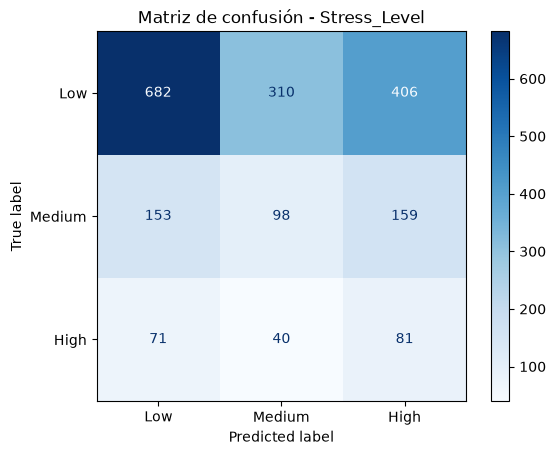

In [44]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test_c, pred_c, labels=CLASES)
ConfusionMatrixDisplay(cm, display_labels=CLASES).plot(cmap="Blues")
plt.title("Matriz de confusión - Stress_Level")
plt.show()

## 4. Resumen automático

Esta celda genera `reportes/resumen_modelos.txt` con el dataset, el preprocesamiento, las variables, los parámetros, las métricas y la interpretación de ambos modelos. Todos los valores se calculan en la ejecución, así que el archivo se actualiza automáticamente cada vez que se ejecuta el notebook, incluido GitHub Actions.

In [45]:
from datetime import datetime
from pathlib import Path
from sklearn.metrics import confusion_matrix, recall_score

# --- Valores de esta ejecución ---
lin = modelo_reg.named_steps["modelo"]
prep_r = modelo_reg.named_steps["prep"]
coef_reg = pd.Series(lin.coef_, index=prep_r.get_feature_names_out())
escala = prep_r.named_transformers_["num"].scale_
cafe_por_taza = coef_reg["num__Coffee_Intake"] / escala[NUMERICAS.index("Coffee_Intake")]
top_coef = coef_reg.reindex(coef_reg.abs().sort_values(ascending=False).index).head(5)

acc_m = accuracy_score(y_test_c, pred_c)
acc_b = accuracy_score(y_test_c, pred_base)
f1_m = f1_score(y_test_c, pred_c, average="macro")
f1_b = f1_score(y_test_c, pred_base, average="macro")
recall_high = recall_score(y_test_c, pred_c, labels=["High"], average=None)[0]
cm_df = pd.DataFrame(
    confusion_matrix(y_test_c, pred_c, labels=CLASES),
    index=[f"real_{c}" for c in CLASES], columns=[f"pred_{c}" for c in CLASES],
)
corr_cafe = df_inicial["Coffee_Intake"].corr(df_inicial["Caffeine_mg"])

lineas = [
    "RESUMEN AUTOMÁTICO - EA2 MODELOS DE PREDICCIÓN Y CLASIFICACIÓN",
    "=" * 70,
    f"Fecha de ejecución: {datetime.now():%Y-%m-%d %H:%M:%S}",
    "",
    "1. DATASET",
    f"Identificador: {DATASET}",
    f"Enlace: https://huggingface.co/datasets/{DATASET}",
    f"Split: {SPLIT}",
    f"Tamaño original: {df_inicial.shape[0]} filas x {df_inicial.shape[1]} columnas",
    "",
    "2. PREPROCESAMIENTO",
    "- Se eliminó ID: es un identificador sin valor predictivo.",
    f"- Se eliminó Caffeine_mg: correlación con Coffee_Intake = {corr_cafe:.2f} (información repetida).",
    f"- Health_Issues: {int(df_inicial['Health_Issues'].isna().sum())} nulos rellenados con 'None' (sin problemas reportados).",
    f"- Duplicados encontrados: {int(df_inicial.duplicated().sum())}.",
    "- Excluidas por fuga de información (construidas a partir de Sleep_Hours): Sleep_Quality, Stress_Level, Health_Issues.",
    "- Numéricas escaladas con StandardScaler; categóricas codificadas con OneHotEncoder(drop='first').",
    "- El preprocesamiento se ajustó solo con el conjunto de entrenamiento (Pipeline de scikit-learn).",
    f"- Columnas: {len(PREDICTORAS)} predictoras originales -> {len(prep_r.get_feature_names_out())} después de transformar.",
    "",
    "3. MODELO DE REGRESIÓN LINEAL",
    "Objetivo: predecir las horas de sueño (Sleep_Hours).",
    f"Variables predictoras: {', '.join(PREDICTORAS)}",
    "Algoritmo: LinearRegression (parámetros predeterminados).",
    f"Configuración: test_size={TEST_SIZE}, random_state={SEMILLA}, entrenamiento={len(X_train_r)}, prueba={len(X_test_r)}.",
    f"MAE: {mae:.3f} h | RMSE: {rmse:.3f} h | R²: {r2:.3f}",
    f"Intercepto: {lin.intercept_:.3f}",
    "Coeficientes de mayor magnitud:",
    top_coef.round(3).to_string(),
    f"Interpretación: el modelo explica el {r2 * 100:.1f}% de la variación del sueño, con un error promedio "
    f"de {mae * 60:.0f} minutos. Cada taza de café adicional se asocia con {abs(cafe_por_taza) * 60:.1f} "
    f"minutos {'menos' if cafe_por_taza < 0 else 'más'} de sueño, manteniendo las demás variables constantes.",
    "",
    "4. MODELO DE CLASIFICACIÓN",
    "Objetivo: clasificar el nivel de estrés (Stress_Level: Low, Medium, High).",
    f"Variables predictoras: {', '.join(PREDICTORAS)}",
    "Algoritmo: LogisticRegression(class_weight='balanced', max_iter=1000).",
    f"Configuración: test_size={TEST_SIZE}, random_state={SEMILLA}, división estratificada por clase.",
    f"Exactitud: {acc_m:.3f} (línea base 'siempre Low': {acc_b:.3f})",
    f"F1 macro: {f1_m:.3f} (línea base: {f1_b:.3f})",
    "Reporte por clase:",
    classification_report(y_test_c, pred_c, labels=CLASES, zero_division=0),
    "Matriz de confusión:",
    cm_df.to_string(),
    f"Interpretación: el F1 macro del modelo ({f1_m:.2f}) {'supera' if f1_m > f1_b else 'no supera'} al de la "
    f"línea base ({f1_b:.2f}). Detecta el {recall_high * 100:.0f}% de los casos de estrés alto, aunque con "
    "muchas falsas alarmas. La clase Medium es la más difícil de distinguir.",
    "",
    "5. CONCLUSIONES Y LIMITACIONES",
    "- Sleep_Quality, Stress_Level y Health_Issues se construyeron a partir de Sleep_Hours; usarlas como",
    "  predictoras habría producido resultados artificialmente buenos (fuga de información).",
    "- Sin esas variables, el consumo de café es la principal señal disponible; las demás casi no se relacionan con el sueño.",
    "- Las clases de estrés están desbalanceadas; por eso se usó F1 macro y class_weight='balanced'.",
    "- Los modelos muestran asociaciones, no relaciones de causa y efecto.",
]

SALIDA = Path.cwd() / "reportes" / "resumen_modelos.txt"
SALIDA.parent.mkdir(parents=True, exist_ok=True)
SALIDA.write_text("\n".join(lineas) + "\n", encoding="utf-8")

print("\n".join(lineas))
print("\nResumen guardado en:", SALIDA)

RESUMEN AUTOMÁTICO - EA2 MODELOS DE PREDICCIÓN Y CLASIFICACIÓN
Fecha de ejecución: 2026-10-13 02:19:18

1. DATASET
Identificador: ADAMlam-16/coffee-data_eda-project
Enlace: https://huggingface.co/datasets/ADAMlam-16/coffee-data_eda-project
Split: train
Tamaño original: 10000 filas x 16 columnas

2. PREPROCESAMIENTO
- Se eliminó ID: es un identificador sin valor predictivo.
- Se eliminó Caffeine_mg: correlación con Coffee_Intake = 1.00 (información repetida).
- Health_Issues: 5941 nulos rellenados con 'None' (sin problemas reportados).
- Duplicados encontrados: 0.
- Excluidas por fuga de información (construidas a partir de Sleep_Hours): Sleep_Quality, Stress_Level, Health_Issues.
- Numéricas escaladas con StandardScaler; categóricas codificadas con OneHotEncoder(drop='first').
- El preprocesamiento se ajustó solo con el conjunto de entrenamiento (Pipeline de scikit-learn).
- Columnas: 10 predictoras originales -> 32 después de transformar.

3. MODELO DE REGRESIÓN LINEAL
Objetivo: prede